In [1]:
#İlk olarak kütüphanelerimizi import ederek başlıyoruz.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
#datasetimizi değişkene atıyoruz.
df = pd.read_csv("googleplaystore.csv")

In [3]:
#ilk bir veri setimizi anlamak için head ile sütun-colon yapısına bakıyoruz.
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
#colon isimlerimizi öğrenmek istiyoruz genel bilgi için.
#Bunları tek bir yerde de yapmıştık fakat ayrı ayrı bakmak istiyorum.
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

In [6]:
#kaç satır,sütun oldugunu görüyoruz.
df.shape

(10841, 13)

In [8]:
#Veri setimizle ilgili verilerde null var mı, kaç satır-sütun olduğunu
#dtypelerını görüyoruz.
#Ki ilk olarak görzümüze şu çarpmalı onlarca sayısal veri seti olmasına rağmen
#değerlimizde rating hariç hepsi object bu şundan dolayı olabilir 
#db'ye kayıtları çekerken mb,+,M gibi verilerle bizlerin önüne gelmiş
#ilk olarak şunu bi kestiyiroruz biraz bi veri temizleme ve dönüşümle işimiz olacka.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [10]:
#verilerimiz arasında ki bağlantılara bakmak istiyoruz fakat burada bizde 1 tane float değer oldugundan dolayı
#çok sağlıklı bir değer göremeyecğiz gibi 
df.describe()
#ki aynen öyle oluyor tek değerlik bir yerimizin oldugunu görüyoruz.


,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


In [12]:
#madem bu kadar baktık bir de eksik verilerimiz var mı onlara bakalım
df.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [14]:
#sütunlarımızın iç değelerinie bakalım onlar bizlere ne vericek.
#yukarıda object olarak verse de toplam değerlerine baktığımızda 
#hangi veri tiplerine uygun olduğunu da bizlere söyleyebiliyor.
df["Reviews"].value_counts()
#hop bingo ne gördük aşağıda dtype:int64 diyor bize fakat yukarıda obj. veriyordu.
#diper veri setlerimizde büyük ihtimal bu sekilde görünüyor.
#Artık kesinleşti ki bunları bir elden geçireceğiz.

Reviews
0         596
1         272
2         214
3         175
4         137
         ... 
342912      1
4272        1
5517        1
4057        1
398307      1
Name: count, Length: 6002, dtype: int64

In [18]:
#bakalım reviews içerisinde unique değerlerimiz neler diye
df["Reviews"].unique()
#Şu anda hepsi sayısal değer olarak bizlerin önüne geliyor.
#Yani ne anlayabiliriz burada bu set int olmaya uygun.


array(['159', '967', '87510', ..., '603', '1195', '398307'],
      shape=(6002,), dtype=object)

In [19]:
#astype ile veri dönülümleri uygun olan değeşlerimizi direkt olarak çevirebiliyoruz.
#fakat dedikten sonra bize bir hata döndürdü
#ValueError: invalid literal for int() with base 10: '3.0M' yani diyor ki 
#sen çevirmeye çalştın eyvallah ama senin içerinde 3.0M adında bir değer var
#bu değer benim seni dönüştürmeme engelliyor buna bi el at veya bu şekilde bırak diyor.
#yani değiştirmeye uygun değilmiş
#df["Reviews"] = df["Reviews"].astype(int)

In [21]:
#peki o zaman şunu yapalım ben reviews içerisinde numeric olanların toplamlarını alsam
#Bunların toplam kaç tane olduguna baksam zaten 10841 tane değerim vardı.as
#Hop ne dedi bize 10841 tane elemanım vardı zaten 10840 tanesi numericmiş 
#yani 1 tane değerim 3.0M değeriymiş o zaman direkt olarak onu alsam
#1 değer oldugundan dolayı silsem başım ağrır mı ağrımaz bi erişelim ona
df["Reviews"].str.isnumeric().sum()

np.int64(10840)

In [23]:
#Tamam o satırı bulacağız ama nasıl bulacağız ne yapıyorduk setimizin içerisinden bir değeri almak istediğimiz zamanda direkt olarak  df[["Reviews"]] şeklinde o veriye erişiyorduk fakat bu bize neyi veriyor true olanları getiriyor biz o zaman deriz ki kardeşim sen bana true olanları değil true olmayanları getir yani falseları geitr.
#df[~] diyince bize bu sefer tam tersini yani olmayanları gösterecek
df[~df["Reviews"].str.isnumeric()]
#Hop bingi 3.0M değerini bize verdi bunu buradan çıkartıp devam edeceğiz.

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [24]:
#Her zaman verilerle çalılrken bir kopya üzerinden çalımamız bizler için garanti bir iş olur.
df_clean = df.copy()

In [25]:
#kopyasını aldıktan sonra artık direkt olarak o veriyi silmek istiyorum.
#drop ile beraber direkt siliyorum neyine bakıp siliyorum indexine
df_clean = df_clean.drop(df_clean.index[10472])

In [27]:
#info diyerek silebildik mi bakalım ve sonra kaldığımız astype 'ı yapalım
df_clean.info()
#ve evet istediğimiz 10840 değerini aldık artık çevireceğiz.

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  object 
 1   Category        10840 non-null  object 
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  object 
 4   Size            10840 non-null  object 
 5   Installs        10840 non-null  object 
 6   Type            10839 non-null  object 
 7   Price           10840 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10840 non-null  object 
 10  Last Updated    10840 non-null  object 
 11  Current Ver     10832 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.2+ MB


In [28]:
df_clean["Reviews"] = df_clean["Reviews"].astype(int)

In [30]:
#tekrar info diyip bakalım çevirebildik mi
df_clean.info()
#ilk verimizin çevirisini yaptık.

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  object 
 1   Category        10840 non-null  object 
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            10840 non-null  object 
 5   Installs        10840 non-null  object 
 6   Type            10839 non-null  object 
 7   Price           10840 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10840 non-null  object 
 10  Last Updated    10840 non-null  object 
 11  Current Ver     10832 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 1.2+ MB


In [31]:
df_clean.describe()
#zamanda artık int olduğundna dolayı reviews'ıda göreceğiz

,Rating,Reviews
count,9366.000000,1.084000e+04
mean,4.191757,4.441529e+05
std,0.515219,2.927761e+06
min,1.000000,0.000000e+00
25%,4.000000,3.800000e+01
50%,4.300000,2.094000e+03
75%,4.500000,5.477550e+04
max,5.000000,7.815831e+07


In [33]:
#veri tipi dönüşümleine devem edelim.
#size değerimiz de sayılsal bir değer onun countlarına bakalım
df_clean["Size"].value_counts()
#zten bize diyor ki dtype:int64 çevir problem yok diyor.
#fakat az önceki gibi hata almamak için ilk önce sunlara bakalım
#size içerisinde nelerimiz var onlara bakalım unique ile

Size
Varies with device    1695
11M                    198
12M                    196
14M                    194
13M                    191
                      ... 
430k                     1
429k                     1
200k                     1
460k                     1
619k                     1
Name: count, Length: 461, dtype: int64

In [65]:
df_clean["Size"].unique()
#Mlerimiz k larımız var şimdi şöyle yapabiliriz işimizin kolaylaşması için
#bunların hepisi m lerimizi kb'a çevirelim 000 koysak zaten kb'a çevirelecekler
#toplu bir şekilde bizlerin önünde kalsın

array(['19000', '14000', '8.7000', '25000', '2.8000', '5.6000', '29000',
       '33000', '3.1000', '28000', '12000', '20000', '21000', '37000',
       '2.7000', '5.5000', '17000', '39000', '31000', '4.2000', '7.0000',
       '23000', '6.0000', '6.1000', '4.6000', '9.2000', '5.2000', '11000',
       '24000', nan, '9.4000', '15000', '10000', '1.2000', '26000',
       '8.0000', '7.9000', '56000', '57000', '35000', '54000', '201k',
       '3.6000', '5.7000', '8.6000', '2.4000', '27000', '2.5000', '16000',
       '3.4000', '8.9000', '3.9000', '2.9000', '38000', '32000', '5.4000',
       '18000', '1.1000', '2.2000', '4.5000', '9.8000', '52000', '9.0000',
       '6.7000', '30000', '2.6000', '7.1000', '3.7000', '22000', '7.4000',
       '6.4000', '3.2000', '8.2000', '9.9000', '4.9000', '9.5000',
       '5.0000', '5.9000', '13000', '73000', '6.8000', '3.5000', '4.0000',
       '2.3000', '7.2000', '2.1000', '42000', '7.3000', '9.1000', '55000',
       '23k', '6.5000', '1.5000', '7.5000', '51000'

In [71]:
#nasıl yapacağız peki, m gördüğümüz yere replace et neyi 0 çünkü m zaten mb
#m yazanlara 3 tane 0 k yazanları sil diyeceğiz
df_clean["Size"] = df_clean["Size"].str.replace("M","000")
df_clean["Size"] = df_clean["Size"].str.replace("k","")


In [72]:
#dönüşümlerimiz oldu mu bakalaım.
df_clean["Size"].unique()
#Varies with device diye bir değer var bunu dasilelim
#silsek verilerimiz oynayacak direkt olarak nan yazdıralım

array(['19000', '14000', '8.7000', '25000', '2.8000', '5.6000', '29000',
       '33000', '3.1000', '28000', '12000', '20000', '21000', '37000',
       '2.7000', '5.5000', '17000', '39000', '31000', '4.2000', '7.0000',
       '23000', '6.0000', '6.1000', '4.6000', '9.2000', '5.2000', '11000',
       '24000', nan, '9.4000', '15000', '10000', '1.2000', '26000',
       '8.0000', '7.9000', '56000', '57000', '35000', '54000', '201',
       '3.6000', '5.7000', '8.6000', '2.4000', '27000', '2.5000', '16000',
       '3.4000', '8.9000', '3.9000', '2.9000', '38000', '32000', '5.4000',
       '18000', '1.1000', '2.2000', '4.5000', '9.8000', '52000', '9.0000',
       '6.7000', '30000', '2.6000', '7.1000', '3.7000', '22000', '7.4000',
       '6.4000', '3.2000', '8.2000', '9.9000', '4.9000', '9.5000',
       '5.0000', '5.9000', '13000', '73000', '6.8000', '3.5000', '4.0000',
       '2.3000', '7.2000', '2.1000', '42000', '7.3000', '9.1000', '55000',
       '23', '6.5000', '1.5000', '7.5000', '51000', 

In [73]:
#Varies with device gördüpümüz yere nan joy bir şey yazma diyecez.
#önceki parametrelerde str işlem yapıyorduk burada .str kullanmayacağız
df_clean["Size"] = df_clean["Size"].replace("Varies with device",np.nan)

In [74]:
df_clean["Size"].unique()
#nanlara döndürdük. Zaten yoktu olayan bir data en azından oladmıgını düzenledik

array(['19000', '14000', '8.7000', '25000', '2.8000', '5.6000', '29000',
       '33000', '3.1000', '28000', '12000', '20000', '21000', '37000',
       '2.7000', '5.5000', '17000', '39000', '31000', '4.2000', '7.0000',
       '23000', '6.0000', '6.1000', '4.6000', '9.2000', '5.2000', '11000',
       '24000', nan, '9.4000', '15000', '10000', '1.2000', '26000',
       '8.0000', '7.9000', '56000', '57000', '35000', '54000', '201',
       '3.6000', '5.7000', '8.6000', '2.4000', '27000', '2.5000', '16000',
       '3.4000', '8.9000', '3.9000', '2.9000', '38000', '32000', '5.4000',
       '18000', '1.1000', '2.2000', '4.5000', '9.8000', '52000', '9.0000',
       '6.7000', '30000', '2.6000', '7.1000', '3.7000', '22000', '7.4000',
       '6.4000', '3.2000', '8.2000', '9.9000', '4.9000', '9.5000',
       '5.0000', '5.9000', '13000', '73000', '6.8000', '3.5000', '4.0000',
       '2.3000', '7.2000', '2.1000', '42000', '7.3000', '9.1000', '55000',
       '23', '6.5000', '1.5000', '7.5000', '51000', 

In [75]:
#kesirli ifadelerden olustugu içinde float dönüşümü ypaıyoruz
df_clean["Size"] = df_clean["Size"].astype(float)

In [76]:
df_clean["Size"]

0        19000.0
1        14000.0
2            8.7
3        25000.0
4            2.8
          ...   
10836    53000.0
10837        3.6
10838        9.5
10839        NaN
10840    19000.0
Name: Size, Length: 10840, dtype: float64

In [79]:
#karakter temizliği installs değerimizde + lar var ve obj. olarak gösteriyor dtype:int64 veriyor sorugmuzda
df_clean["Installs"].value_counts()

Installs
1,000,000+        1579
10,000,000+       1252
100,000+          1169
10,000+           1054
1,000+             907
5,000,000+         752
100+               719
500,000+           539
50,000+            479
5,000+             477
100,000,000+       409
10+                386
500+               330
50,000,000+        289
50+                205
5+                  82
500,000,000+        72
1+                  67
1,000,000,000+      58
0+                  14
0                    1
Name: count, dtype: int64

In [81]:
df_clean["Installs"].unique()

array(['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+',
       '50,000+', '1,000,000+', '10,000,000+', '5,000+', '100,000,000+',
       '1,000,000,000+', '1,000+', '500,000,000+', '50+', '100+', '500+',
       '10+', '1+', '5+', '0+', '0'], dtype=object)

In [84]:
#ayriyetten verileimizde price da aynı durumda ve int64 olarak veriyor.
#buraya da bir el atıcaz
df_clean["Price"].value_counts()

Price
0         10040
$0.99       148
$2.99       129
$1.99        73
$4.99        72
          ...  
$19.90        1
$1.75         1
$14.00        1
$4.85         1
$1.04         1
Name: count, Length: 92, dtype: int64

In [85]:
#böyle durumlarda direkt teker teker yapmaktansa kaldırılacak karakter ve temizlenecek colonlarımızı atacak onun üzerinden desek ki 
#kardeşim sen hepsini dolaş benim sana verdiğim değerleri ykaaldığonda kaldır o değerleri
#akla ne geliyor değişken tanımlayıp teker teker dolasacağımızdan da for.
chars_to_remove = ["+",",","$"]
cols_to_remove=["Installs","Price"]

In [86]:
#tekte halledeceğimiz döngümüz
for item in chars_to_remove:
    for cols in cols_to_remove:
        df_clean[cols] = df_clean[cols].str.replace(item,"")

In [87]:
df_clean["Price"].unique()

array(['0', '4.99', '3.99', '6.99', '1.49', '2.99', '7.99', '5.99',
       '3.49', '1.99', '9.99', '7.49', '0.99', '9.00', '5.49', '10.00',
       '24.99', '11.99', '79.99', '16.99', '14.99', '1.00', '29.99',
       '12.99', '2.49', '10.99', '1.50', '19.99', '15.99', '33.99',
       '74.99', '39.99', '3.95', '4.49', '1.70', '8.99', '2.00', '3.88',
       '25.99', '399.99', '17.99', '400.00', '3.02', '1.76', '4.84',
       '4.77', '1.61', '2.50', '1.59', '6.49', '1.29', '5.00', '13.99',
       '299.99', '379.99', '37.99', '18.99', '389.99', '19.90', '8.49',
       '1.75', '14.00', '4.85', '46.99', '109.99', '154.99', '3.08',
       '2.59', '4.80', '1.96', '19.40', '3.90', '4.59', '15.46', '3.04',
       '4.29', '2.60', '3.28', '4.60', '28.99', '2.95', '2.90', '1.97',
       '200.00', '89.99', '2.56', '30.99', '3.61', '394.99', '1.26',
       '1.20', '1.04'], dtype=object)

In [88]:
df_clean["Installs"].unique()

array(['10000', '500000', '5000000', '50000000', '100000', '50000',
       '1000000', '10000000', '5000', '100000000', '1000000000', '1000',
       '500000000', '50', '100', '500', '10', '1', '5', '0'], dtype=object)

In [90]:
#Şimdi direkt dönüşümlerini yapalım
df_clean["Price"] = df_clean["Price"].astype(float)

In [91]:
df_clean["Installs"] = df_clean["Installs"].astype(int)

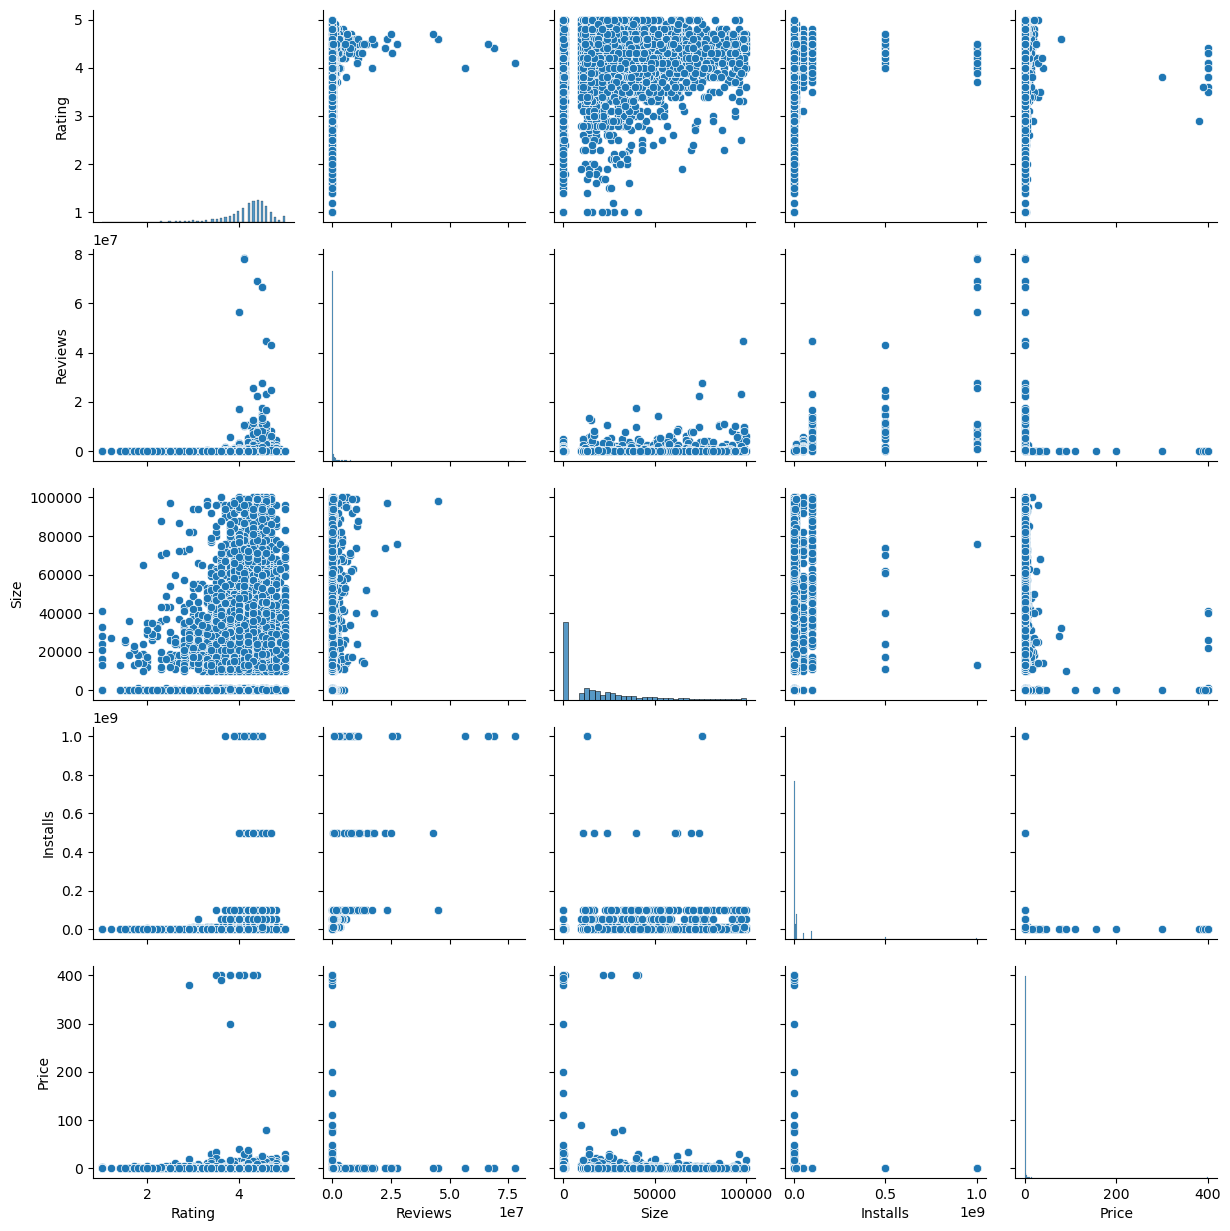

In [92]:
#genel tüm verilerimiz artık daha temiz şöyle bir pairplot ile genel yorumlamamızaı kolaylaştıracak verimizi getirelim
sns.pairplot(df_clean)

In [ ]:
df_clean["Last Updated"]

In [ ]:
df_clean["Last Updated"].unique()
#string olarakr girilmiş.

In [ ]:
#date objesine çevirme. 
df_clean["Last Updated"] = pd.to_datetime(df_clean["Last Updated"])

In [ ]:
#Ekstradan bazen tarih çok mnemliyse ayrı
#gün ay yıl olarak da verebiliriz.
#direkt içerisindeki  günü aldırırız
df_clean["Day"] = df_clean["Last Updated"].dt.day
df_clean["Month"] = df_clean["Last Updated"].dt.month
df_clean["Year"] = df_clean["Last Updated"].dt.year


In [ ]:
df_clean[df_clean.duplicated("App")].shape
#duplice verileri görürüz.

In [ ]:
df_clean=df_clean.drop_duplicates(subset=["App"],keep='first')

In [ ]:
df_clean.info()
#9659'a kadar düştü

In [ ]:
numeric_features = [feature for feature in df_clean.columns if df_clean[feature].dtype !='O']
categorical_features = [feature for feature in df_clean.columns if df_clean[feature].dtype =='O']

In [ ]:
plt.figure(figsize=(15,10))

for i in range (0,len(numeric_features)):
    plt.subplot(5,3,i+1)
    sns.kdeplot(x=df_clean[numeric_features[i]],color="b",fill=True)
    plt.xlabel([numeric_features[i]])
    plt.tight_layout
plt.show()

In [ ]:
plt.figure(figsize=(15,5))
category = ["Type","Content Rating"]
for i in range (0,len(category)):
    plt.subplot(1,2,i+1)
    sns.countplot(x=df_clean[category[i]],color="b",fill=True)
    plt.xlabel([category[i]])
    plt.tight_layout
plt.show()